# Exploratory Data Analysis: NYC 311 Street Condition Requests, 2025

**Question:** Can we predict, at the moment a DOT Street Condition request is filed, whether it will be **recorded as closed within 48 hours** (`closed_48h` = 1)?

**Input:** `data/street_conditions_2025_labeled.csv` (made by `src/data_collection.ipynb`: all 12 months of 2025, 70,322 labelled requests)
**Output:** exploratory figures in this notebook, and three explanatory figures saved to `figures/` for the midterm report.

### EDA goals and why (based on lectures 2, 4, 5 and 10 and the midterm rubric)

| # | Goal | Why it matters |
| --- | --- | --- |
| 1 | **Check data quality**: missing values, impossible values, duplicates | Lecture 2: approach a dataset with healthy skepticism; problems found here decide the preprocessing |
| 2 | **Understand the target**: class balance and the closure-time distribution | Defines the ML problem (binary classification, lecture 1); an imbalanced target changes the baseline and metric |
| 3 | **Look at each feature alone**, with a plot type that fits its data type | Lecture 4: continuous → histogram, categorical → bar plot, ordinal → bar plot **in the correct order**; spot rare categories and skew |
| 4 | **Look at each feature against the target** | Lecture 4 column pairs: categorical vs categorical → stacked bar; continuous vs categorical → category-specific histograms / box plot; shows which features carry signal |
| 5 | **Check the time structure** | Lectures 5 and 10: if the data changes over time it is not i.i.d., and the split must be by time |
| 6 | **Turn the best findings into 3 explanatory figures** | Rubric: three figures with a catchy headline, a clear message, labelled axes and a caption |

Sections 1–5 are **exploratory** (many quick plots for us); section 6 is **explanatory** (three polished plots for the report).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)

# Colours used in every plot (validated for colour-blind readers)
BLUE = "#2a78d6"      # closed within 48 h  /  the highlighted category
ORANGE = "#eb6834"    # not closed within 48 h
GREY = "#b4b2ab"      # context bars in the explanatory figures
INK = "#52514e"       # secondary text and reference lines

# Correct order for the ordinal time features (lecture 4: never let pandas sort them alphabetically)
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

figures_folder = Path("../figures")
figures_folder.mkdir(exist_ok=True)

## 0. Load the data and create the intake-time features

The labelled file has the raw 311 columns plus `closure_hours` and the target `closed_48h`. The features below use **only information known when the request is filed** (the `created_date`), so they can be used for prediction.

In [2]:
data = pd.read_csv(
    "../data/street_conditions_2025_labeled.csv",
    parse_dates=["created_date", "closed_date"],
    dtype={"unique_key": str, "incident_zip": str},
    low_memory=False,
)

print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
print("Date range:", data["created_date"].min(), "to", data["created_date"].max())

Rows: 70322
Columns: 38
Date range: 2025-01-01 02:27:33 to 2025-12-31 23:39:14


In [3]:
# Time features from the filing time
data["submission_hour"] = data["created_date"].dt.hour
data["submission_month"] = data["created_date"].dt.month
data["submission_day_of_week"] = pd.Categorical(
    data["created_date"].dt.day_name(), categories=DAY_ORDER, ordered=True
)
data["is_weekend"] = (data["created_date"].dt.dayofweek >= 5).astype(int)

# 'Unspecified' means missing
data["borough"] = data["borough"].replace("Unspecified", np.nan)

# Flag rows without coordinates (they are kept, not dropped)
data["location_missing"] = data["latitude"].isna().astype(int)

**History-count features** (from the team's feature list): how many requests were filed in the 24 hours / 7 days *before* each request. Only **earlier** requests are counted, so no future information leaks in.

To make this fast for 70,000 rows we sort by time and use `np.searchsorted`, which finds where a value would be inserted into a sorted array: the position of time `t` = the number of requests filed strictly before `t`.

In [4]:
# Sort by filing time; searchsorted needs sorted times
data = data.sort_values(["created_date", "unique_key"]).reset_index(drop=True)


def count_previous(times, window):
    """For each time t in a sorted array, count the times in [t - window, t)."""
    before_t = np.searchsorted(times, times, side="left")                  # requests strictly before t
    before_window = np.searchsorted(times, times - window, side="left")    # requests before t - window
    return before_t - before_window


all_times = data["created_date"].values
data["requests_previous_24h"] = count_previous(all_times, np.timedelta64(24, "h"))

# Same idea inside each group (same borough / same problem type)
for column, new_column in [("borough", "borough_requests_previous_7d"),
                           ("descriptor", "problem_requests_previous_7d")]:
    data[new_column] = np.nan
    for group_name, group_index in data.groupby(column).groups.items():
        group_times = data.loc[group_index, "created_date"].values      # already sorted
        data.loc[group_index, new_column] = count_previous(group_times, np.timedelta64(7, "D"))

# The first week of January has no December 2024 data, so its counts are too low
data["history_incomplete"] = (data["created_date"] < "2025-01-08").astype(int)

display(data[["created_date", "borough", "descriptor", "requests_previous_24h",
              "borough_requests_previous_7d", "problem_requests_previous_7d"]].sample(5, random_state=0))

,created_date,borough,descriptor,requests_previous_24h,borough_requests_previous_7d,problem_requests_previous_7d
50519,2025-08-27 10:43:42,BROOKLYN,Blocked - Construction,219,376.0,62.0
39457,2025-06-30 20:47:33,QUEENS,Cave-in,247,640.0,358.0
41583,2025-07-11 11:10:49,QUEENS,Pothole,248,393.0,569.0
70307,2025-12-31 19:51:19,BROOKLYN,Pothole,161,223.0,484.0
13081,2025-03-09 13:52:00,QUEENS,Pothole,129,546.0,1188.0


## 1. Data quality (lecture 2)

In [5]:
# Missing values in the columns we care about
columns_of_interest = ["created_date", "closed_date", "closure_hours", "closed_48h", "descriptor",
                       "borough", "incident_zip", "latitude", "longitude", "address_type",
                       "open_data_channel_type"]

missing_table = pd.DataFrame({
    "missing_count": data[columns_of_interest].isna().sum(),
    "missing_percent": (data[columns_of_interest].isna().mean() * 100).round(1),
})
display(missing_table)

print("Duplicate request IDs:", data["unique_key"].duplicated().sum())

,missing_count,missing_percent
created_date,0,0.0
closed_date,3475,4.9
closure_hours,3475,4.9
closed_48h,0,0.0
descriptor,0,0.0
borough,132,0.2
incident_zip,749,1.1
latitude,19601,27.9
longitude,19601,27.9
address_type,0,0.0


Duplicate request IDs: 0


In [6]:
# Is the missing location random? No: it follows the address type
location_by_type = pd.crosstab(data["address_type"], data["location_missing"], margins=True)
location_by_type.columns = ["has_location", "missing_location", "total"]
display(location_by_type)

,has_location,missing_location,total
address_type,,,
ADDRESS,27739,9,27748
BLOCKFACE,163,19476,19639
INTERSECTION,22663,116,22779
PLACE,72,0,72
PLACENAME,26,0,26
UNRECOGNIZED,58,0,58
All,50721,19601,70322


In [7]:
# Odd closure times: exactly 0 hours, and very long ones
zero = data["closure_hours"] == 0
print("Closure time exactly 0 hours:", zero.sum(), f"({zero.mean():.1%})")
print("Channel of the 0-hour requests:", data.loc[zero, "open_data_channel_type"].value_counts().to_dict())
print("Closure time over 1 year:", (data["closure_hours"] > 24 * 365).sum())
print("Missing closure time (still open, labelled 0):", data["closure_hours"].isna().sum())

Closure time exactly 0 hours: 3276 (4.7%)
Channel of the 0-hour requests: {'UNKNOWN': 3276}
Closure time over 1 year: 13
Missing closure time (still open, labelled 0): 3475


**Data-quality findings**
- No duplicate request IDs.
- **28% of requests have no latitude/longitude**, and almost all of them are `BLOCKFACE` requests (a stretch of street, not a point). This is *not* random: dropping them would remove a whole request type, so we keep them and use `location_missing`.
- **3,276 requests (4.7%) were closed in exactly 0 hours, all from the `UNKNOWN` channel**: likely records created and closed by DOT staff, not complaints from the public. The team must decide whether to keep them.
- 3,475 requests had no closure date; the team labelled them 0 (still open long after 48 hours).

## 2. The target variable

closed_48h
0    25967
1    44355
Name: count, dtype: int64
closed_48h
1    0.631
0    0.369
Name: proportion, dtype: float64


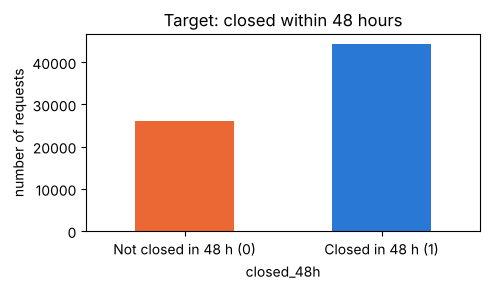

In [8]:
# Class balance
target_counts = data["closed_48h"].value_counts().sort_index()
print(target_counts)
print(data["closed_48h"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 3))
target_counts.plot.bar(color=[ORANGE, BLUE])
plt.xticks([0, 1], ["Not closed in 48 h (0)", "Closed in 48 h (1)"], rotation=0)
plt.ylabel("number of requests")
plt.title("Target: closed within 48 hours")
plt.tight_layout()
plt.show()

count    63571.0
mean        72.7
std        235.5
min          0.0
10%          8.2
25%         18.8
50%         27.6
75%         71.0
90%        142.8
99%        626.6
max      12122.4
Name: closure_hours, dtype: float64


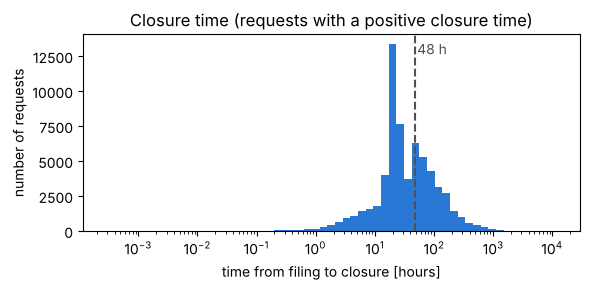

In [9]:
# Closure time is very skewed (minutes to years), so use log-spaced bins and a log x-axis (lecture 4)
hours = data.loc[data["closure_hours"] > 0, "closure_hours"]
print(hours.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(1))

bins = np.logspace(np.log10(hours.min()), np.log10(hours.max()), 60)
plt.figure(figsize=(6, 3))
plt.hist(hours, bins=bins, color=BLUE)
plt.axvline(48, color=INK, linestyle="--")
plt.text(52, plt.ylim()[1] * 0.9, "48 h", color=INK)
plt.semilogx()
plt.xlabel("time from filing to closure [hours]")
plt.ylabel("number of requests")
plt.title("Closure time (requests with a positive closure time)")
plt.tight_layout()
plt.show()

**Target findings:** 63.1% of requests are closed within 48 hours and 36.9% are not, so the classes are **moderately imbalanced**. A model that always predicts 1 would already be 63% accurate, so that is the baseline to beat. The median closure time is 26 hours, which puts the 48-hour cut-off in the middle of the distribution.

## 3. Each feature on its own (lecture 4)

### 3a. Categorical features → bar plots

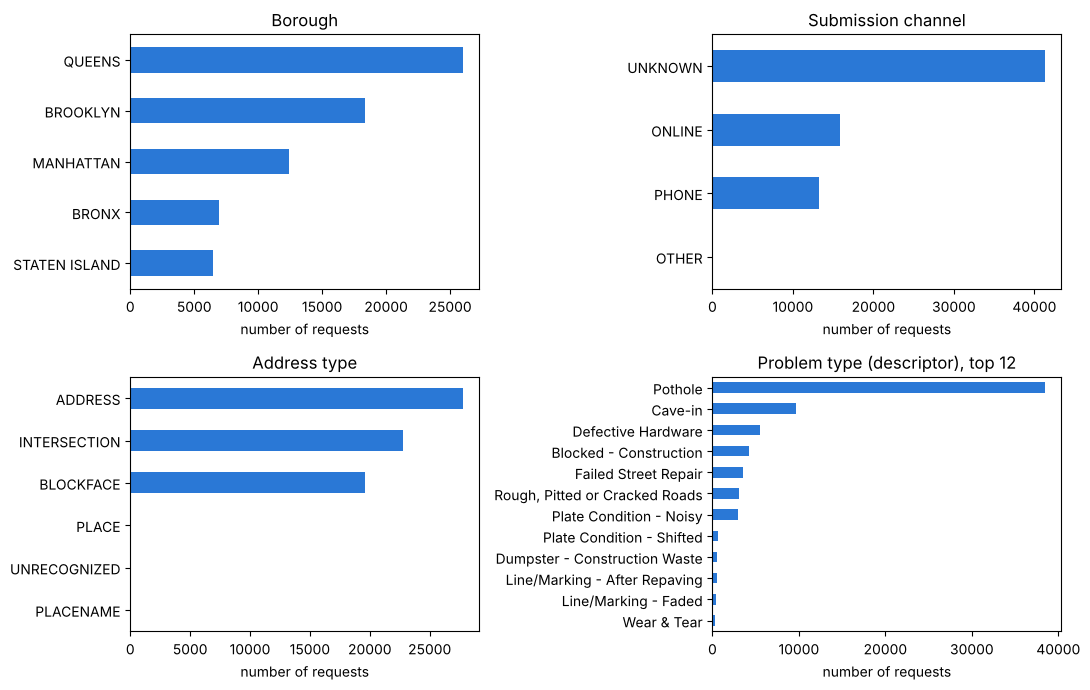

Number of descriptor categories: 21
Descriptor categories with fewer than 100 requests: 7


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

data["borough"].value_counts().plot.barh(ax=axes[0, 0], color=BLUE)
axes[0, 0].set_xlabel("number of requests")
axes[0, 0].set_title("Borough")

data["open_data_channel_type"].value_counts().plot.barh(ax=axes[0, 1], color=BLUE)
axes[0, 1].set_xlabel("number of requests")
axes[0, 1].set_title("Submission channel")

data["address_type"].value_counts().plot.barh(ax=axes[1, 0], color=BLUE)
axes[1, 0].set_xlabel("number of requests")
axes[1, 0].set_title("Address type")

data["descriptor"].value_counts().head(12).plot.barh(ax=axes[1, 1], color=BLUE)
axes[1, 1].set_xlabel("number of requests")
axes[1, 1].set_title("Problem type (descriptor), top 12")

for ax in axes.flat:
    ax.invert_yaxis()           # largest category on top
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Number of descriptor categories:", data["descriptor"].nunique())
print("Descriptor categories with fewer than 100 requests:", (data["descriptor"].value_counts() < 100).sum())

### 3b. Ordinal time features → bar plots in the correct order

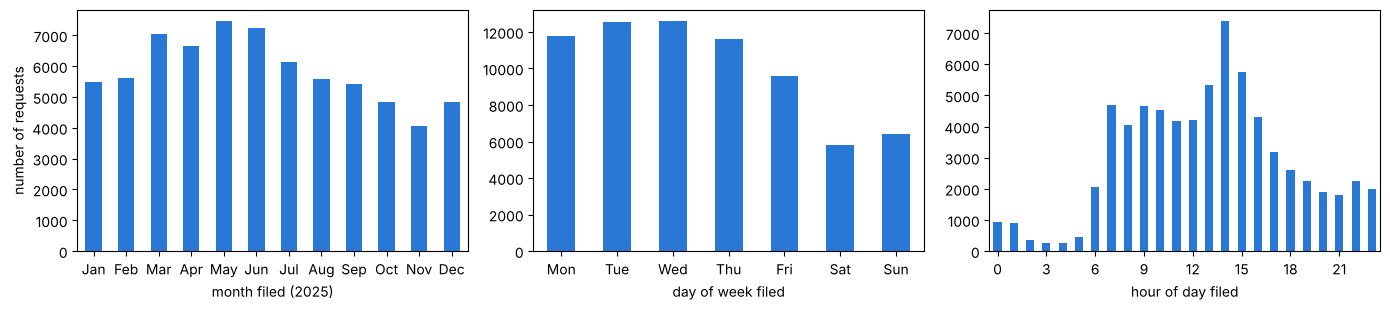

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))

data["submission_month"].value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE)
axes[0].set_xticklabels(MONTH_LABELS, rotation=0)
axes[0].set_xlabel("month filed (2025)")
axes[0].set_ylabel("number of requests")

data["submission_day_of_week"].value_counts().reindex(DAY_ORDER).plot.bar(ax=axes[1], color=BLUE)
axes[1].set_xticklabels([d[:3] for d in DAY_ORDER], rotation=0)
axes[1].set_xlabel("day of week filed")

data["submission_hour"].value_counts().sort_index().plot.bar(ax=axes[2], color=BLUE)
axes[2].set_xlabel("hour of day filed")
axes[2].set_xticks(range(0, 24, 3))
axes[2].set_xticklabels(range(0, 24, 3), rotation=0)

plt.tight_layout()
plt.show()

### 3c. Continuous features → histograms

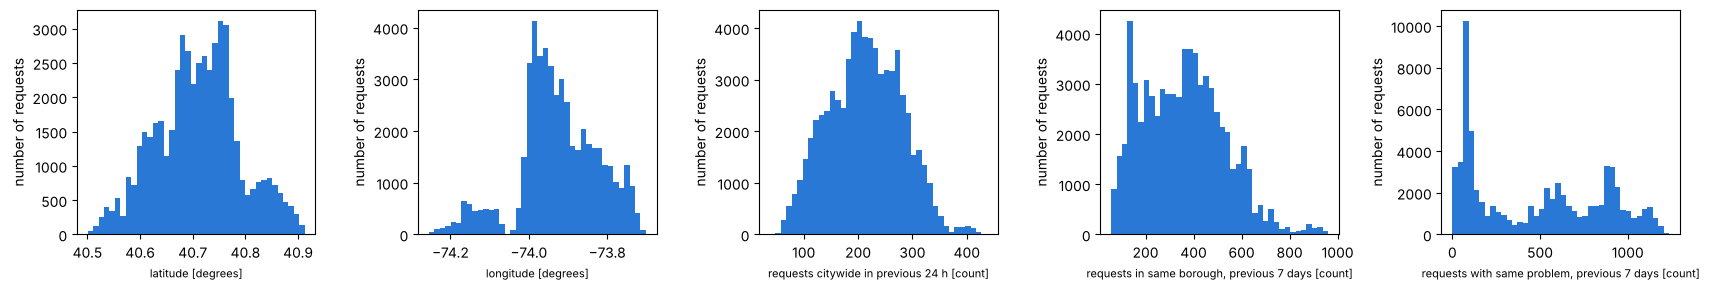

In [12]:
continuous_features = {
    "latitude": "latitude [degrees]",
    "longitude": "longitude [degrees]",
    "requests_previous_24h": "requests citywide in previous 24 h [count]",
    "borough_requests_previous_7d": "requests in same borough, previous 7 days [count]",
    "problem_requests_previous_7d": "requests with same problem, previous 7 days [count]",
}

# Leave out the first week of January for the history counts (they are too low there)
complete = data["history_incomplete"] == 0

fig, axes = plt.subplots(1, 5, figsize=(17, 3))
for ax, (column, label) in zip(axes, continuous_features.items()):
    values = data[column] if column in ["latitude", "longitude"] else data.loc[complete, column]
    values.plot.hist(ax=ax, bins=40, color=BLUE)
    ax.set_xlabel(label, fontsize=8)
    ax.set_ylabel("number of requests")
plt.tight_layout()
plt.show()

**Single-feature findings**
- Queens and Brooklyn have the most requests; potholes are 55% of all requests; **7 of the 21 descriptor categories have fewer than 100 requests** and could be grouped as "Other".
- The `UNKNOWN` channel is the largest (59%).
- Few requests are filed on weekends or at night.
- `problem_requests_previous_7d` is spread out, because potholes are so much more common than other problems.

## 4. Each feature against the target (lecture 4: column pairs)

### 4a. Categorical vs categorical → stacked bar of fractions

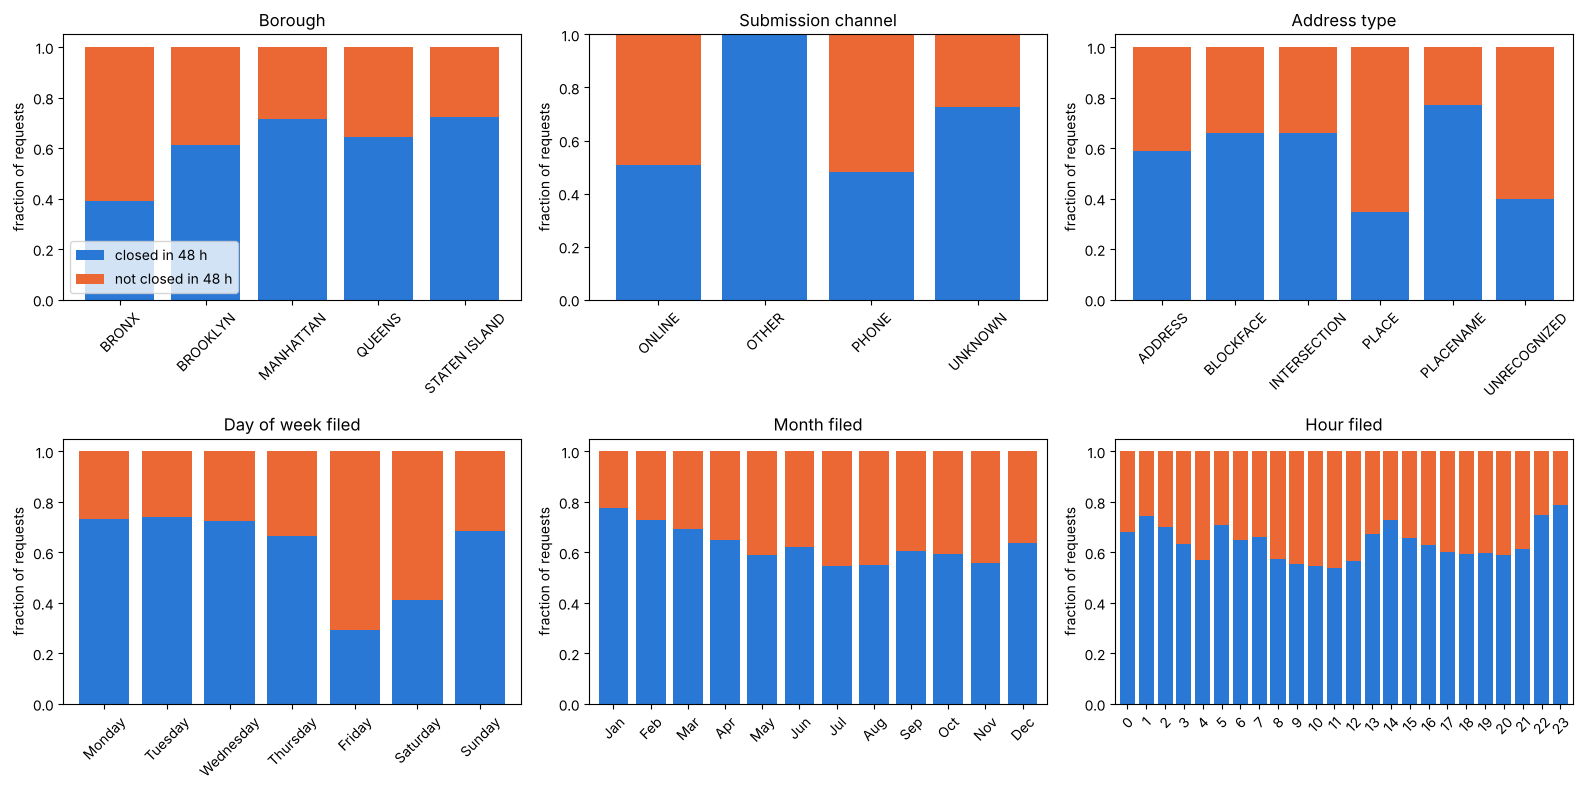

In [13]:
def plot_fraction_closed(column, title, order=None, ax=None):
    """Stacked bar: fraction of requests closed / not closed within 48 h, per category."""
    count_matrix = data.groupby([column, "closed_48h"], observed=True).size().unstack()
    count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)      # rows sum to 1
    if order is not None:
        count_matrix_norm = count_matrix_norm.reindex(order)
    count_matrix_norm = count_matrix_norm[[1, 0]]                               # closed first
    count_matrix_norm.columns = ["closed in 48 h", "not closed in 48 h"]
    count_matrix_norm.plot(kind="bar", stacked=True, color=[BLUE, ORANGE], ax=ax, legend=False, width=0.8)
    ax.set_title(title)
    ax.set_ylabel("fraction of requests")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    return count_matrix


fig, axes = plt.subplots(2, 3, figsize=(16, 8))
plot_fraction_closed("borough", "Borough", ax=axes[0, 0])
plot_fraction_closed("open_data_channel_type", "Submission channel", ax=axes[0, 1])
plot_fraction_closed("address_type", "Address type", ax=axes[0, 2])
plot_fraction_closed("submission_day_of_week", "Day of week filed", order=DAY_ORDER, ax=axes[1, 0])
plot_fraction_closed("submission_month", "Month filed", ax=axes[1, 1])
plot_fraction_closed("submission_hour", "Hour filed", ax=axes[1, 2])
axes[1, 1].set_xticklabels(MONTH_LABELS)
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

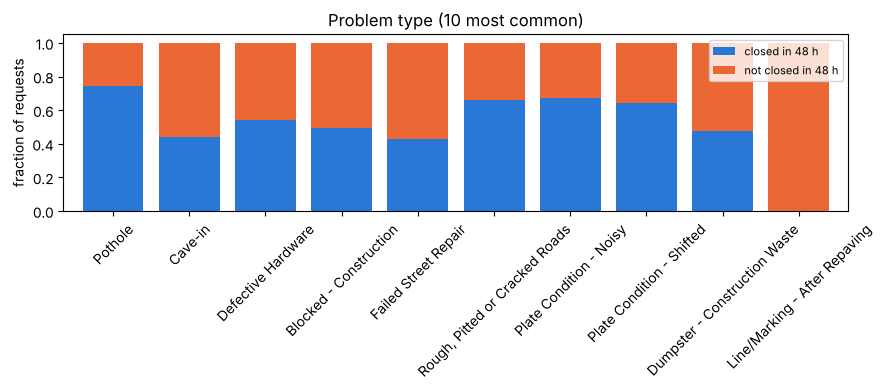

,requests,share_closed_48h
borough,,
QUEENS,25980,0.645
BROOKLYN,18375,0.613
MANHATTAN,12386,0.715
BRONX,6955,0.390
STATEN ISLAND,6494,0.722


,requests,share_closed_48h
open_data_channel_type,,
UNKNOWN,41288,0.726
ONLINE,15842,0.506
PHONE,13191,0.482
OTHER,1,1.000


,requests,share_closed_48h
submission_day_of_week,,
Wednesday,12570,0.726
Tuesday,12544,0.740
Monday,11794,0.733
Thursday,11623,0.666
Friday,9569,0.292
Sunday,6411,0.683
Saturday,5811,0.411


,requests,share_closed_48h
descriptor,,
Pothole,38430,0.745
Cave-in,9647,0.443
Defective Hardware,5490,0.541
Blocked - Construction,4245,0.492
Failed Street Repair,3487,0.429
"Rough, Pitted or Cracked Roads",3121,0.659
Plate Condition - Noisy,2927,0.672
Plate Condition - Shifted,622,0.640
Dumpster - Construction Waste,584,0.474


In [14]:
# Same plot for the 10 most common problem types
top_descriptors = data["descriptor"].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(9, 4))
plot_fraction_closed("descriptor", "Problem type (10 most common)", order=top_descriptors, ax=ax)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# The numbers behind the plots
for column in ["borough", "open_data_channel_type", "submission_day_of_week", "descriptor"]:
    table = data.groupby(column, observed=True)["closed_48h"].agg(requests="size", share_closed_48h="mean")
    display(table.sort_values("requests", ascending=False).head(10).round(3))

**Why is Friday so low?** A request filed on Friday has its 48-hour window over the weekend. Below: on which weekday do closures actually happen?

In [15]:
closure_day = data["closed_date"].dt.day_name().value_counts().reindex(DAY_ORDER)
print(closure_day)
print(f"Share of closures on Saturday or Sunday: {closure_day[['Saturday', 'Sunday']].sum() / closure_day.sum():.1%}")

# Does the Friday effect hold inside every channel? (rows = day filed, columns = channel)
friday_check = pd.crosstab(data["submission_day_of_week"], data["open_data_channel_type"],
                           values=data["closed_48h"], aggfunc="mean").round(2)
display(friday_check[["UNKNOWN", "ONLINE", "PHONE"]])

closed_date
Monday       12998
Tuesday      14007
Wednesday    13709
Thursday     11783
Friday       11825
Saturday      1354
Sunday        1171
Name: count, dtype: int64
Share of closures on Saturday or Sunday: 3.8%


open_data_channel_type,UNKNOWN,ONLINE,PHONE
submission_day_of_week,,,
Monday,0.80,0.64,0.62
Tuesday,0.81,0.66,0.62
Wednesday,0.80,0.62,0.60
Thursday,0.77,0.53,0.50
Friday,0.38,0.20,0.16
Saturday,0.57,0.25,0.19
Sunday,0.80,0.51,0.47


### 4b. Continuous vs categorical → category-specific histograms and box plots

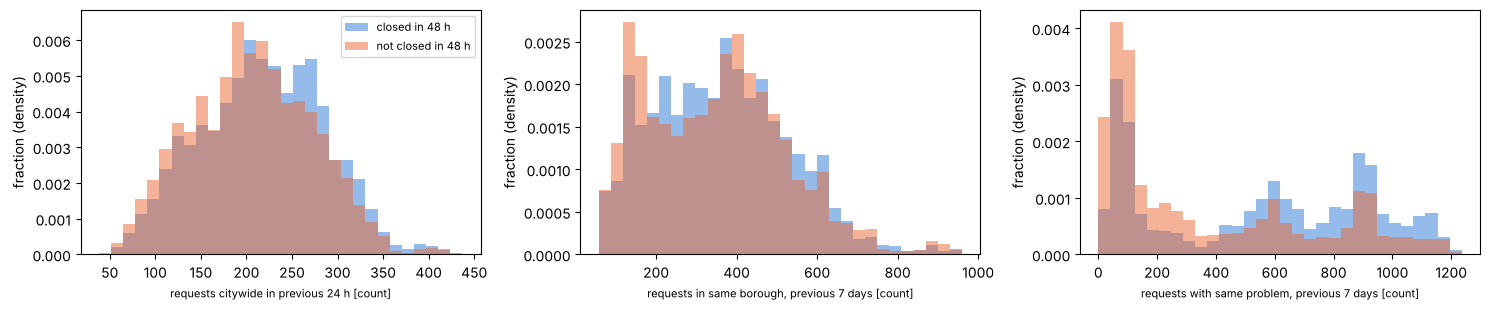

,requests_previous_24h,borough_requests_previous_7d,problem_requests_previous_7d
closed_48h,,,
0,205.0,355.5,195.0
1,218.0,360.0,592.0


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
history_features = ["requests_previous_24h", "borough_requests_previous_7d", "problem_requests_previous_7d"]

for ax, column in zip(axes, history_features):
    values = data.loc[complete, column]
    bin_range = (values.min(), values.max())
    for label, colour, name in [(1, BLUE, "closed in 48 h"), (0, ORANGE, "not closed in 48 h")]:
        ax.hist(values[data.loc[complete, "closed_48h"] == label], bins=30, range=bin_range,
                density=True, alpha=0.5, color=colour, label=name)
    ax.set_xlabel(continuous_features[column], fontsize=8)
    ax.set_ylabel("fraction (density)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

display(data[complete].groupby("closed_48h")[history_features].median())

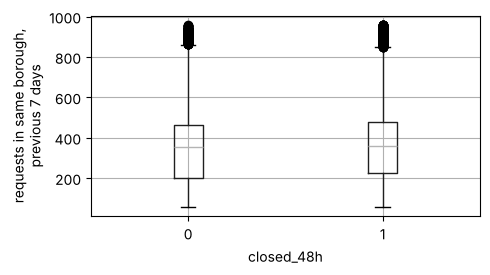

In [17]:
# Box plot (lecture 4): borough workload in the previous 7 days, by outcome
data[complete].boxplot(column="borough_requests_previous_7d", by="closed_48h", figsize=(5, 3))
plt.suptitle("")
plt.title("")
plt.xlabel("closed_48h")
plt.ylabel("requests in same borough,\nprevious 7 days")
plt.tight_layout()
plt.show()

### 4c. Continuous vs continuous → scatter plot of location, coloured by outcome

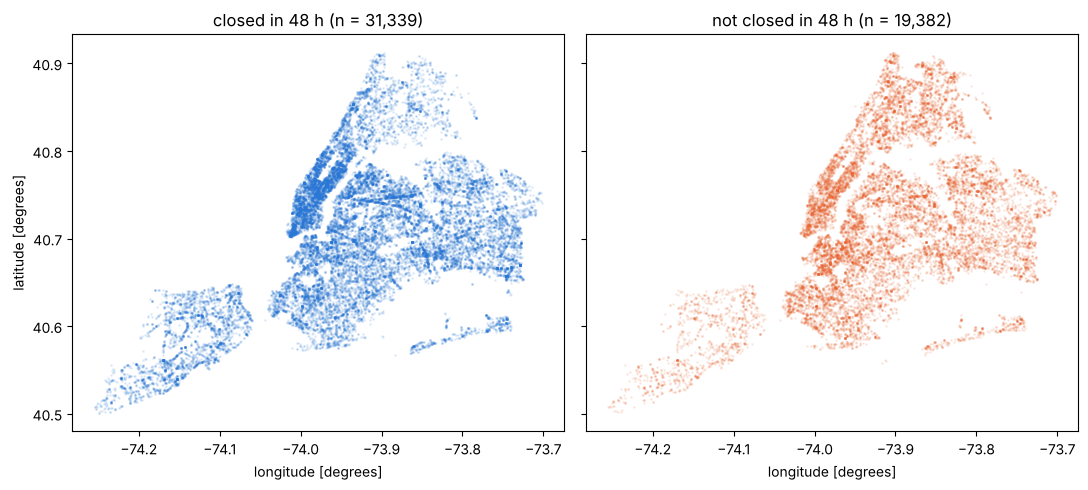

In [18]:
located = data[data["location_missing"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (label, colour, name) in zip(axes, [(1, BLUE, "closed in 48 h"), (0, ORANGE, "not closed in 48 h")]):
    subset = located[located["closed_48h"] == label]
    ax.scatter(subset["longitude"], subset["latitude"], s=1, alpha=0.1, color=colour)
    ax.set_title(f"{name} (n = {len(subset):,})")
    ax.set_xlabel("longitude [degrees]")
axes[0].set_ylabel("latitude [degrees]")
plt.tight_layout()
plt.show()

**Feature-vs-target findings**
- **Day of week is the strongest pattern:** about 73% of Monday–Wednesday requests close within 48 hours, but only **29% on Friday** and 41% on Saturday. Only **3.8% of closures happen on a weekend**, so a 48-hour window that covers the weekend rarely ends in a closure. The effect holds in every channel.
- **Problem type:** potholes 75%, cave-ins 44%, failed street repairs 43%; line-marking and "Wear & Tear" requests are almost never closed in 48 hours.
- **Channel:** `UNKNOWN` 73% vs online 51% and phone 48%.
- **Borough:** the Bronx (39%) is far below every other borough (61–72%).
- **Hour:** late-night requests close more often (they are first in line the next morning).
- **History counts:** citywide and same-borough counts overlap a lot between the classes (weak on their own). The same-problem count differs strongly (median 592 vs 195), but mostly because potholes are both very common and closed fast, so it largely repeats the problem type.

## 5. Time structure: is the data i.i.d.? (lectures 5 and 10)

,requests,share_closed_48h
submission_month,,
1,5474,0.777
2,5622,0.728
3,7032,0.692
4,6659,0.651
5,7449,0.590
6,7242,0.622
7,6137,0.547
8,5590,0.552
9,5411,0.607


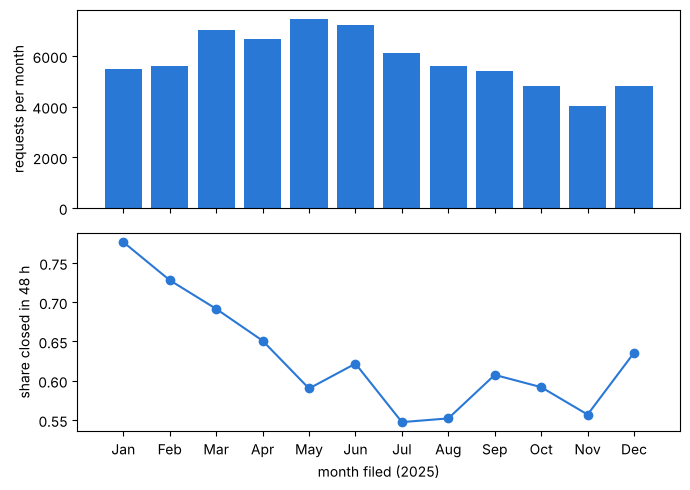

In [19]:
monthly = data.groupby("submission_month").agg(requests=("closed_48h", "size"),
                                               share_closed_48h=("closed_48h", "mean"))
display(monthly.round(3))

fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
axes[0].bar(monthly.index, monthly["requests"], color=BLUE)
axes[0].set_ylabel("requests per month")
axes[1].plot(monthly.index, monthly["share_closed_48h"], marker="o", color=BLUE)
axes[1].set_ylabel("share closed in 48 h")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(MONTH_LABELS)
axes[1].set_xlabel("month filed (2025)")
plt.tight_layout()
plt.show()

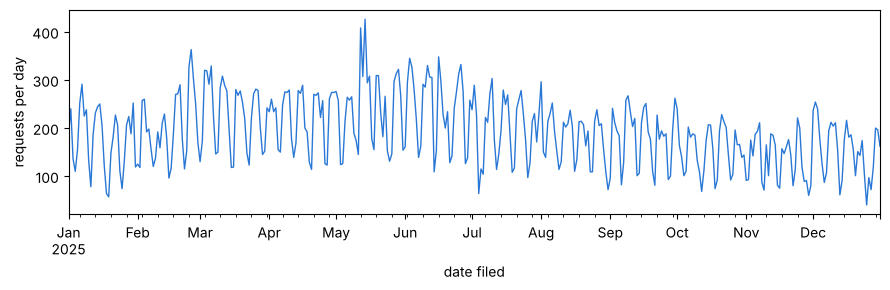

Lag-1 autocorrelation: 0.57
Lag-7 autocorrelation: 0.74


In [20]:
# Daily number of requests: neighbouring days look alike (not independent)
daily = data.set_index("created_date").resample("D").size()

plt.figure(figsize=(9, 3))
daily.plot(color=BLUE, linewidth=1)
plt.ylabel("requests per day")
plt.xlabel("date filed")
plt.tight_layout()
plt.show()

# Autocorrelation (lecture 10): correlation of the daily count with itself 1 and 7 days earlier
print("Lag-1 autocorrelation:", round(daily.autocorr(lag=1), 2))
print("Lag-7 autocorrelation:", round(daily.autocorr(lag=7), 2))

**Time-structure findings:** the share closed in 48 hours falls from **78% in January to 55–56% in July, August and November**, and daily counts are strongly autocorrelated with a weekly cycle. The data is **not i.i.d.**, so the train/validation/test split should follow time (lecture 10), not a random shuffle.

## 6. Three explanatory figures for the report

Each figure has one message, a headline that states it, labelled axes, and a caption (the caption text is a draft to rewrite in your own words). Grey bars give context; blue marks what the headline is about.

In [21]:
def finish_explanatory(fig, ax, headline, subtitle, filename):
    """Common styling for the explanatory figures: headline, subtitle, light frame, save."""
    fig.text(0.01, 0.97, headline, fontsize=13, fontweight="bold", ha="left", va="top")
    fig.text(0.01, 0.89, subtitle, fontsize=9.5, color=INK, ha="left", va="top")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    fig.savefig(figures_folder / filename, dpi=200, bbox_inches="tight")
    plt.show()


overall_share = data["closed_48h"].mean()

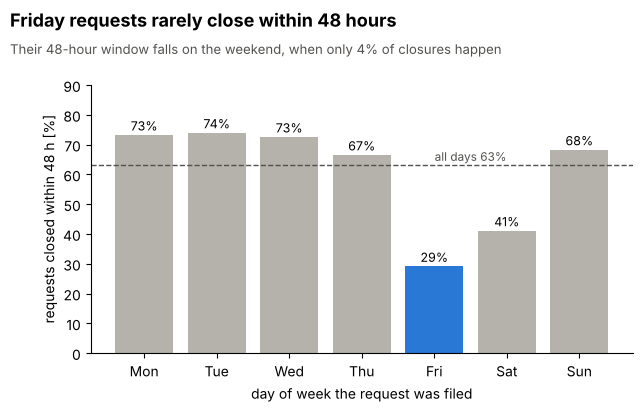

In [22]:
# Figure 1: day of week
by_day = data.groupby("submission_day_of_week", observed=True)["closed_48h"].mean().reindex(DAY_ORDER)
colours = [BLUE if day == "Friday" else GREY for day in DAY_ORDER]

fig, ax = plt.subplots(figsize=(7, 4))
fig.subplots_adjust(top=0.78)
ax.bar([d[:3] for d in DAY_ORDER], by_day * 100, color=colours)
for i, value in enumerate(by_day):
    ax.text(i, value * 100 + 1.5, f"{value:.0%}", ha="center", fontsize=9)
ax.axhline(overall_share * 100, color=INK, linestyle="--", linewidth=1)
ax.text(4.5, overall_share * 100 + 1.5, f"all days {overall_share:.0%}", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(0, 90)
ax.set_ylabel("requests closed within 48 h [%]")
ax.set_xlabel("day of week the request was filed")
finish_explanatory(fig, ax,
                   "Friday requests rarely close within 48 hours",
                   "Their 48-hour window falls on the weekend, when only 4% of closures happen",
                   "fig1_day_of_week.png")

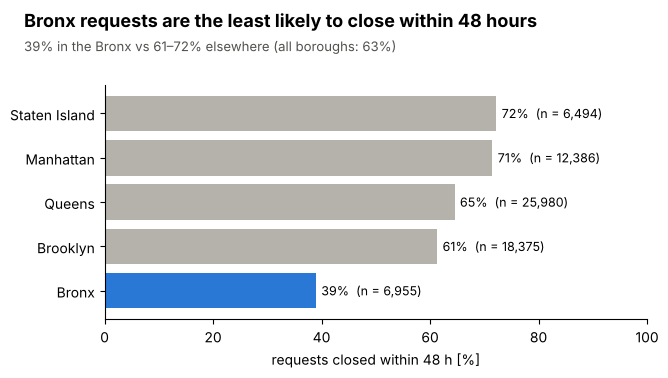

In [23]:
# Figure 2: borough
by_borough = data.groupby("borough")["closed_48h"].agg(["mean", "size"]).sort_values("mean")
colours = [BLUE if b == "BRONX" else GREY for b in by_borough.index]

fig, ax = plt.subplots(figsize=(7, 3.6))
fig.subplots_adjust(top=0.76)
ax.barh(by_borough.index.str.title(), by_borough["mean"] * 100, color=colours)
for i, (share, n) in enumerate(zip(by_borough["mean"], by_borough["size"])):
    ax.text(share * 100 + 1, i, f"{share:.0%}  (n = {n:,})", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("requests closed within 48 h [%]")
finish_explanatory(fig, ax,
                   "Bronx requests are the least likely to close within 48 hours",
                   f"39% in the Bronx vs 61–72% elsewhere (all boroughs: {overall_share:.0%})",
                   "fig2_borough.png")

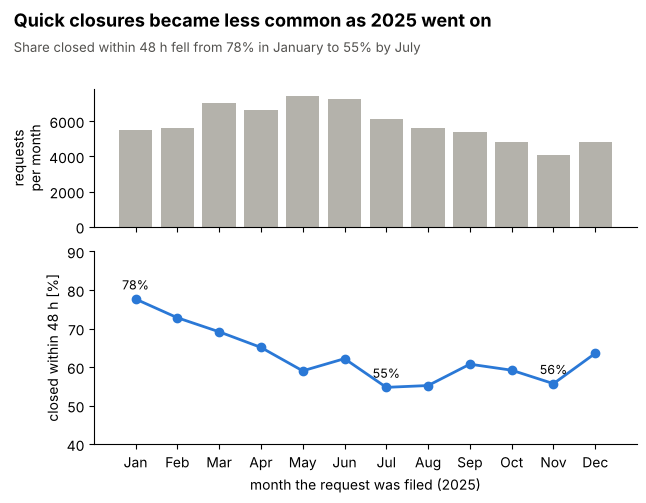

In [24]:
# Figure 3: month (two panels instead of a dual axis)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
fig.subplots_adjust(top=0.82, hspace=0.15)

axes[0].bar(monthly.index, monthly["requests"], color=GREY)
axes[0].set_ylabel("requests\nper month")

axes[1].plot(monthly.index, monthly["share_closed_48h"] * 100, marker="o", color=BLUE, linewidth=2)
for month in [1, 7, 11]:
    value = monthly.loc[month, "share_closed_48h"]
    axes[1].text(month, value * 100 + 2.5, f"{value:.0%}", ha="center", fontsize=9)
axes[1].set_ylim(40, 90)
axes[1].set_ylabel("closed within 48 h [%]")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(MONTH_LABELS)
axes[1].set_xlabel("month the request was filed (2025)")
for ax in axes:
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.text(0.01, 0.98, "Quick closures became less common as 2025 went on", fontsize=13, fontweight="bold", va="top")
fig.text(0.01, 0.92, "Share closed within 48 h fell from 78% in January to 55% by July", fontsize=9.5, color=INK, va="top")
fig.savefig(figures_folder / "fig3_month.png", dpi=200, bbox_inches="tight")
plt.show()

**Draft captions** (rewrite in your own words for the report; captions count toward the 1,500 words):

- **Figure 1.** Share of 2025 DOT Street Condition requests recorded as closed within 48 hours, by the weekday the request was filed (n = 70,322). The dashed line is the overall share.
- **Figure 2.** Share closed within 48 hours by borough, 2025 (n = 70,190; 132 requests with no borough excluded). The labels give each borough's share and number of requests.
- **Figure 3.** Monthly number of requests (top) and share closed within 48 hours (bottom), 2025 (n = 70,322).

## Summary: what the EDA means for modelling

| Finding | Consequence |
| --- | --- |
| 63% / 37% target split | Baseline accuracy is 63%; report precision/recall or ROC AUC, not only accuracy |
| Friday/Saturday effect, weekend closures rare | Keep day of week and hour; consider a feature like "weekend hours inside the 48-hour window" |
| Strong differences by problem type, channel and borough | Keep these categorical features; group the 7 rare descriptors into "Other" |
| 28% missing coordinates, not at random | Keep the rows; use `location_missing` and borough instead of dropping |
| 3,276 zero-hour closures, all `UNKNOWN` channel | Team decision: keep or exclude, and say so in the report |
| Share closed changes month to month; strong autocorrelation | Not i.i.d. → split by time (train on earlier months, test on later) |
| Citywide/borough counts overlap between classes; same-problem count mostly repeats the problem type | Test them in the model rather than assume they help; watch for redundancy with `descriptor` |